# Dar_002 — P1 temperature–illumination and temperature–terrain relationships

**Question:** Within the same region and phase product, how is temperature associated with
solar/Earth visibility, sky view, permanent-shadow class, elevation and slope?

**Inputs:** completed [Dar_001](Dar_001_temperature_local_time.ipynb) regional Diviner rows;
D02–D04 2016 south-polar native illumination rasters **and their source labels**;
D06 selected complete LOLA elevation, slope, elevation-error, effective-resolution and
spot-count maps. D05's original seven footprints are carried forward from Dar_001.

Reuse notebook 25's containing-native-pixel join and separate coverage reporting. The old
05/13/25 notebooks are references, not required completed runs. The unfinished slope-error
file is explicitly **not used**; no values are invented to replace it. Terrain joins describe
native 40 m context at 240 m thermal centers, not a new 40 m thermal measurement.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'outline.md').is_file() and (p / 'notebooks').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook from the repository or its subfolders')
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'darrel stuff/EDA'))
DATA_ROOT = ROOT / 'darrel stuff/data'
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from moon_p1_analysis import (region_footprints, local_time_hours, prepare_regional_diviner,
    temperature_summary, documented_illumination, sample_containing_pixels, native_window)
import moon_p1_analysis
def short(name):
    return name.split('_', 2)[-1].replace('_', ' ')
def save_figure(run, fig, name):
    fig.savefig(run.path(name + '.png'), dpi=140, bbox_inches='tight')
    display(fig)
    plt.close(fig)
print('Read-only raw inputs:', DATA_ROOT)

import rasterio
from notebooks.shared.inspection import verify_run, check_input

Read-only raw inputs: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data


## 1. Pin an accepted thermal run and verify units

Set `THERMAL_RUN_ID` for reproducibility, or use the latest **completed** local Dar_001 run.
Partial/failed runs are never substituted. The original 2016 labels must agree with TIFF
scale and offset; mask nodata **before** decoding. PSR is a binary class, visibility is a
fraction and sky view is steradians. The old generated unit-policy file is not guessed:
this notebook checks the available publisher labels directly and records them.

In [2]:
THERMAL_RUN_ID = None
thermal_run = latest_completed_run(ROOT, 'analysis/dar_001_temperature_local_time', THERMAL_RUN_ID)
expected = verify_run(thermal_run)
def accepted(path):
    check_input(path, expected, {})
    return path
footprints = json.loads(accepted(thermal_run / 'region_footprints.json').read_text(encoding='utf-8'))
regions = list(footprints)
layers = documented_illumination(DATA_ROOT)
lola_root = DATA_ROOT / 'moon/lola_product90/large_area_dem'
terrain_layers = {
    'elevation_m': ('LDEM_80S_40MPP_ADJ.TIF', 'm; radius reference 1737400 m'),
    'slope_deg': ('LDSM_80S_40MPP_ADJ.TIF', 'degree'),
    'elevation_error_m': ('LDEM_80S_40MPP_ADJ_ERR.TIF', 'm'),
    'effective_resolution_m': ('LDEM_80S_40MPP_ADJ_EFFRES.TIF', 'm'),
    'spot_count': ('LDEC_80S_40MPP_ADJ.TIF', 'count'),
}
for key, (name, unit) in terrain_layers.items():
    layers[key] = {'path': lola_root / name, 'unit': unit}
    if not layers[key]['path'].is_file(): raise FileNotFoundError(layers[key]['path'])
print('Thermal source:', thermal_run)
print('Explicitly excluded: unfinished LDSM_80S_40MPP_ADJ_ERR.TIF; no slope-error analysis claimed')
display(pd.DataFrame([{'variable': k, 'unit': v['unit'], 'source': str(v['path'].relative_to(ROOT))}
                      for k,v in layers.items()]))

Accepted local analysis/dar_001_temperature_local_time run: 20261106T082643415392Z_4e6a0b
Thermal source: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_001_temperature_local_time\20261106T082643415392Z_4e6a0b
Explicitly excluded: unfinished LDSM_80S_40MPP_ADJ_ERR.TIF; no slope-error analysis claimed


,variable,unit,source
0,solar_visibility,fraction,darrel stuff\data\moon\illumination_2016\geoti...
1,earth_visibility,fraction,darrel stuff\data\moon\illumination_2016\geoti...
2,permanent_shadow,binary,darrel stuff\data\moon\illumination_2016\geoti...
3,sky_view_sr,steradian,darrel stuff\data\moon\illumination_2016\geoti...
4,elevation_m,m; radius reference 1737400 m,darrel stuff\data\moon\lola_product90\large_ar...
5,slope_deg,degree,darrel stuff\data\moon\lola_product90\large_ar...
6,elevation_error_m,m,darrel stuff\data\moon\lola_product90\large_ar...
7,effective_resolution_m,m,darrel stuff\data\moon\lola_product90\large_ar...
8,spot_count,count,darrel stuff\data\moon\lola_product90\large_ar...


## 2. Pairing and comparison design

- One lookup per distinct native Diviner center; merge back with `many_to_one` validation.
- Keep source pixel row/column IDs, region, Ls, product, local hour, quality context and gaps.
- Main associations: Spearman correlation **within region and source product**, not one
  pooled correlation across all regions/phases. Also stratify by local-hour bin as a check.
- Report paired centers, source pixels, missingness, and constant/insufficient-variable
  cases explicitly. Do not compute p-values treating repeated cells as independent trials.
- Compare PSR classes separately; present fixed-complete-common cohort sensitivity on matched product IDs. Predictor quantile bands use distinct native centers, not repeated phase rows.
- Pixel lookup verifies technical alignment, **not physical co-registration** or footprint
  overlap. Mean visibility maps are static context, not contemporaneous illumination.

In [3]:
PREDICTORS = ['solar_visibility','earth_visibility','sky_view_sr','elevation_m','slope_deg']
def correlation_rows(paired, group_keys, cohort):
    rows = []
    for group, part in paired.groupby(group_keys, observed=True, dropna=False):
        group = group if isinstance(group, tuple) else (group,)
        for variable in PREDICTORS:
            usable = part.loc[part.usable & np.isfinite(part[variable])].copy()
            centers = usable[['clon','clat']].drop_duplicates()
            status = ('insufficient_pairs' if len(centers) < 3 else
                      'constant_variable' if usable[variable].nunique() < 2 or usable.tbol.nunique() < 2 else 'descriptive')
            rho = usable[[variable,'tbol']].corr(method='spearman').iloc[0,1] if status == 'descriptive' else np.nan
            rows.append({**dict(zip(group_keys, group)), 'cohort': cohort, 'variable': variable,
                'available_thermal_rows': int(part.usable.sum()), 'paired_rows': len(usable),
                'paired_native_centers': len(centers),
                'paired_source_pixels': usable[variable + '_pixel'].nunique(),
                'spearman_rho': rho, 'status': status})
    return pd.DataFrame(rows)

def plot_relationships(run, correlations, shadow):
    main = correlations.loc[(correlations.cohort == 'available') & correlations.status.eq('descriptive')]
    fig, axes = plt.subplots(1, len(PREDICTORS), figsize=(18,5), sharey=True, layout='constrained')
    for ax, variable in zip(axes, PREDICTORS):
        for index, region in enumerate(regions):
            group = main.loc[(main.region == region) & (main.variable == variable)]
            # Distribution across products, not an uncertainty interval.
            if len(group):
                q = group.spearman_rho.quantile([.1,.5,.9])
                ax.hlines(index, q.loc[.1], q.loc[.9], color='#176b72', linewidth=3)
                ax.scatter(q.loc[.5], index, color='#d17b45')
        ax.axvline(0, color='black', linewidth=.6)
        ax.set(title=variable.replace('_',' '), xlabel='Within-product Spearman rho', xlim=(-1,1))
        ax.set_yticks(range(len(regions)), [short(r) for r in regions], fontsize=7)
        ax.grid(alpha=.2)
    axes[0].invert_yaxis()
    fig.suptitle('Temperature relationships: median and 10–90% spread across supported phase products\nDescriptive associations, not causal effects, p-values or equipment limits')
    save_figure(run, fig, 'temperature_environment_correlations')
    fig, ax = plt.subplots(figsize=(12,5), layout='constrained')
    for psr, marker in [(0,'o'),(1,'x')]:
        part = shadow.loc[(shadow.permanent_shadow == psr) & (shadow.cohort == 'available')]
        for i, region in enumerate(regions):
            vals = part.loc[part.region == region, 'median_K'].dropna()
            if len(vals): ax.scatter(np.repeat(i + (.1 if psr else -.1),len(vals)),vals,marker=marker,alpha=.3,s=14,
                                    label=f'PSR {psr}' if i == 0 else None)
    ax.set_xticks(range(len(regions)), [short(r) for r in regions], rotation=30, ha='right')
    ax.set(ylabel='Within-product spatial median temperature (K)', title='Separate shadow classes; each point is a supported phase product')
    ax.legend(); ax.grid(alpha=.2)
    save_figure(run, fig, 'temperature_shadow_classes')

## 3. Execute native joins, coverage and relationship EDA

The selected LOLA units follow the original processing/readiness studies and
[Product 90 documentation](https://pgda.gsfc.nasa.gov/products/90); TIFFs retain their native
40 m grid and scale. Error/effective-resolution/count layers are **quality context**, not
temperature uncertainty or independent predictor measurements. Zero LOLA spot counts are reported separately: a finite interpolated DEM value is not proof of a local laser measurement. No arbitrary quality cutoffs
or regression/suitability weights are fitted.

Leibnitz Beta Plateau paired rows: 409327


Malapert Massif paired rows: 766830


deGerlache Kocher Massif paired rows: 629348


Haworth paired rows: 1471015


Faustini Rim A paired rows: 551857


deGerlache Rim 2 paired rows: 523101


Connecting Ridge Extension paired rows: 473891


C:\Users\silen\AppData\Local\Temp\ipykernel_29672\2472535563.py:77: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  shadow = pd.concat(shadow_parts, ignore_index=True)


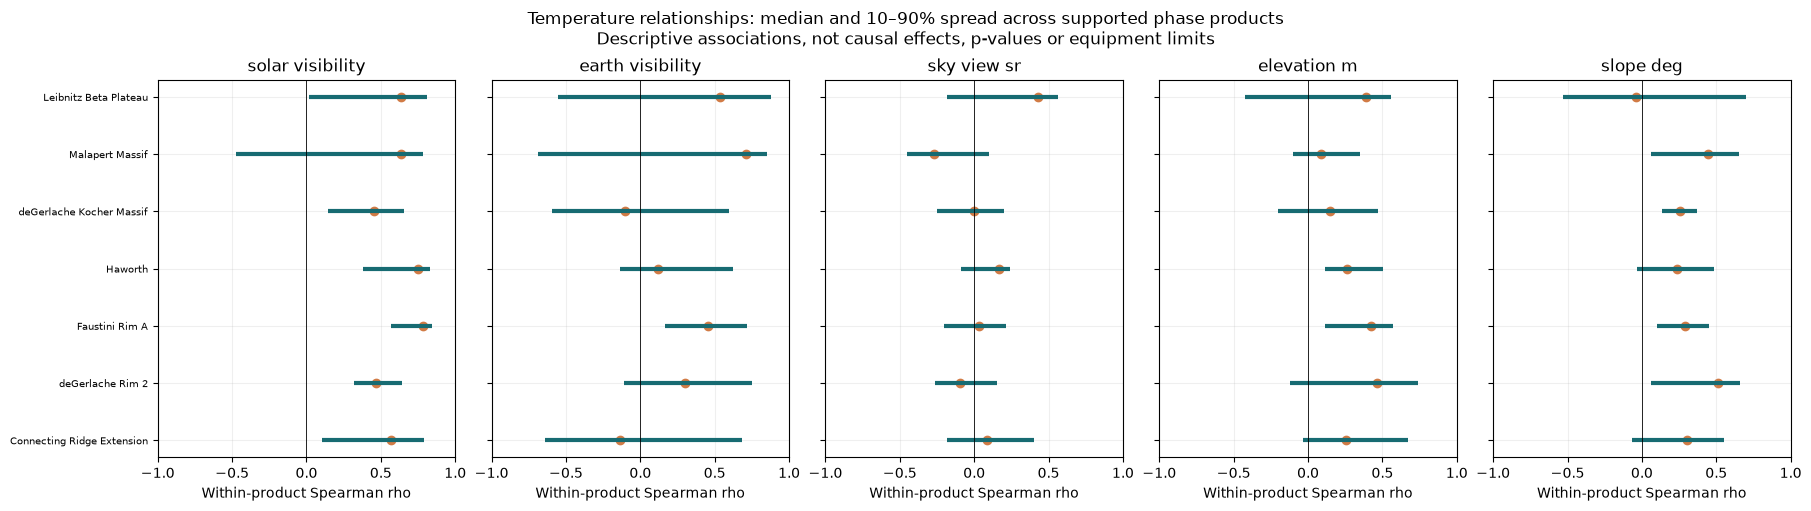

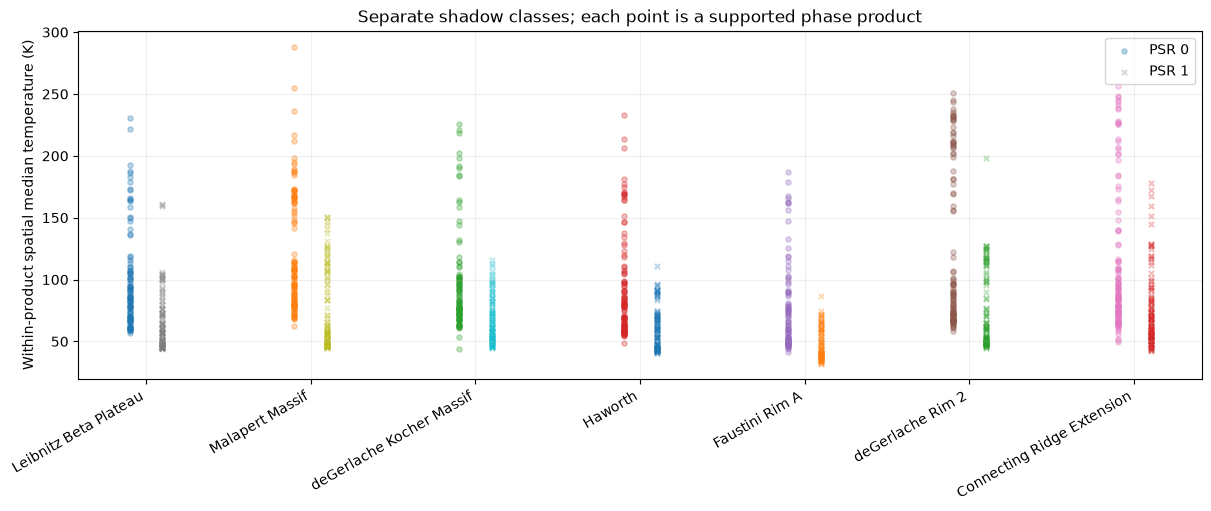

,region,variable,unit,observed_centers,finite_center_lookups,missing_center_lookups,source_resolution_m,source_pixels
0,A3CLR22_10_Leibnitz_Beta_Plateau,solar_visibility,fraction,4422,4422,0,60.0,4422
1,A3CLR22_10_Leibnitz_Beta_Plateau,earth_visibility,fraction,4422,4422,0,60.0,4422
2,A3CLR22_10_Leibnitz_Beta_Plateau,permanent_shadow,binary,4422,4422,0,60.0,4422
3,A3CLR22_10_Leibnitz_Beta_Plateau,sky_view_sr,steradian,4422,4422,0,240.0,4422
4,A3CLR22_10_Leibnitz_Beta_Plateau,elevation_m,m; radius reference 1737400 m,4422,4422,0,40.0,4422
...,...,...,...,...,...,...,...,...
58,A3CLR22_5_Connecting_Ridge_Extension,elevation_m,m; radius reference 1737400 m,7056,7056,0,40.0,7056
59,A3CLR22_5_Connecting_Ridge_Extension,slope_deg,degree,7056,7056,0,40.0,7056
60,A3CLR22_5_Connecting_Ridge_Extension,elevation_error_m,m,7056,7056,0,40.0,7056
61,A3CLR22_5_Connecting_Ridge_Extension,effective_resolution_m,m,7056,7056,0,40.0,7056


,region,observed_native_centers,zero_spot_count_centers,positive_spot_count_centers,missing_spot_count_centers,median_effective_resolution_m,q90_effective_resolution_m,median_elevation_error_m
0,A3CLR22_10_Leibnitz_Beta_Plateau,4422,243,4179,0,18.711585,30.179461,0.139452
1,A3CLR22_11_Malapert_Massif,7569,174,7395,0,15.711732,24.696761,0.123132
2,A3CLR22_12_deGerlache_Kocher_Massif,6972,1163,5809,0,24.406695,46.470085,0.225091
3,A3CLR22_2_Haworth,15500,216,15284,0,15.077662,22.641845,0.119683
4,A3CLR22_3_Faustini_Rim_A,6972,557,6415,0,21.267061,34.797166,0.169069
5,A3CLR22_4_deGerlache_Rim_2,6889,226,6663,0,17.471346,27.451332,0.132705
6,A3CLR22_5_Connecting_Ridge_Extension,7056,522,6534,0,19.718483,33.574146,0.144929


,region,variable,count,median
0,A3CLR22_10_Leibnitz_Beta_Plateau,earth_visibility,103,0.532990
1,A3CLR22_10_Leibnitz_Beta_Plateau,elevation_m,103,0.390598
2,A3CLR22_10_Leibnitz_Beta_Plateau,sky_view_sr,103,0.429674
3,A3CLR22_10_Leibnitz_Beta_Plateau,slope_deg,103,-0.041386
4,A3CLR22_10_Leibnitz_Beta_Plateau,solar_visibility,103,0.634812
5,A3CLR22_11_Malapert_Massif,earth_visibility,113,0.707333
6,A3CLR22_11_Malapert_Massif,elevation_m,113,0.084061
7,A3CLR22_11_Malapert_Massif,sky_view_sr,113,-0.269924
8,A3CLR22_11_Malapert_Massif,slope_deg,113,0.445689
9,A3CLR22_11_Malapert_Massif,solar_visibility,113,0.637677


Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_002_temperature_environment\20261106T082929336242Z_623f9f


In [4]:
config = {'thermal_run': str(thermal_run.relative_to(ROOT)), 'pairing': 'containing native pixel; no interpolation',
          'scope': 'original seven region rectangles and Dar_001 selected phase products',
          'excluded': ['unfinished slope-error map'], 'physical_coregistration': 'not established'}
with Run(ROOT, 'analysis/dar_002_temperature_environment', config,
         'Moon/Thermal/Dar_002_temperature_environment_relationships.ipynb') as run:
    run.input(Path(moon_p1_analysis.__file__))
    run.input(thermal_run / 'provenance.json')
    run.input(thermal_run / 'region_footprints.json')
    for definition in layers.values():
        run.input(definition['path'])
        if 'label' in definition: run.input(definition['label'])
    correlation_parts, local_parts, shadow_parts, coverage_rows, native_rows = [], [], [], [], []
    quality_parts, binned_parts, quality_support_rows = [], [], []
    for region in regions:
        path = accepted(thermal_run / f'regional_observations/{region}.csv.gz')
        run.input(path)
        observations = pd.read_csv(path)
        for flag in ['valid_temperature','usable','complete_common_cohort']:
            if observations[flag].dtype != bool: raise ValueError(f'Invalid boolean encoding: {flag}')
        centers = observations[['clon','clat','x_m','y_m']].drop_duplicates()
        assert not centers.duplicated(['clon','clat']).any()
        bounds = footprints[region]['bounds_m']
        for variable, definition in layers.items():
            values, pixels, resolution = sample_containing_pixels(definition['path'], centers, bounds)
            centers[variable], centers[variable + '_pixel'] = values, pixels
            finite = values[np.isfinite(values)]
            if variable in ['solar_visibility','earth_visibility'] and ((finite < 0) | (finite > 1)).any():
                raise ValueError(f'Visibility fraction outside [0,1]: {variable}')
            if variable == 'permanent_shadow' and not np.isin(finite, [0.,1.]).all():
                raise ValueError('Decoded PSR is not binary')
            coverage_rows.append({'region': region, 'variable': variable, 'unit': definition['unit'],
                'observed_centers': len(centers), 'finite_center_lookups': len(finite),
                'missing_center_lookups': len(values)-len(finite), 'source_resolution_m': resolution[0],
                'source_pixels': len(set(p for p,v in zip(pixels,values) if np.isfinite(v)))})
            if 'label' in definition:
                with rasterio.open(definition['path']) as src:
                    _, native, inside = native_window(src, bounds)
                    vals = native[inside & np.isfinite(native)]
                    native_rows.append({'region': region,'variable': variable,'unit': definition['unit'],
                        'inside_native_centers': int(inside.sum()),'valid_native_centers': len(vals),
                        'mean': float(np.mean(vals)) if len(vals) else np.nan,
                        **{f'q{int(q*100)}':float(np.quantile(vals,q)) if len(vals) else np.nan for q in [.1,.5,.9]}})
        quality_support_rows.append({'region': region, 'observed_native_centers': len(centers),
            'zero_spot_count_centers': int(centers.spot_count.eq(0).sum()),
            'positive_spot_count_centers': int(centers.spot_count.gt(0).sum()),
            'missing_spot_count_centers': int(centers.spot_count.isna().sum()),
            'median_effective_resolution_m': float(centers.effective_resolution_m.median()),
            'q90_effective_resolution_m': float(centers.effective_resolution_m.quantile(.9)),
            'median_elevation_error_m': float(centers.elevation_error_m.median())})
        paired = observations.merge(centers, on=['clon','clat','x_m','y_m'], how='left', validate='many_to_one')
        assert len(paired) == len(observations)
        paired.to_csv(run.path(f'paired_observations/{region}.csv.gz'),index=False,compression={'method':'gzip','mtime':0,'compresslevel':3})
        for cohort, part in [('available', paired), ('complete_common', paired.loc[paired.complete_common_cohort])]:
            # Fixed cohorts only use the common products that defined those cohorts.
            if cohort == 'complete_common':
                run.input(accepted(thermal_run / 'findings.json'))
                meta = json.loads((thermal_run / 'findings.json').read_text(encoding='utf-8'))
                part = part.loc[part.source_product.isin(meta['common_products'])]
            correlation_parts.append(correlation_rows(part,['region','seasonal_ls_bin','source_product'],cohort))
            local_parts.append(correlation_rows(part,['region','seasonal_ls_bin','source_product','local_time_bin_h'],cohort))
            shadow = temperature_summary(part.loc[part.permanent_shadow.notna()],
                ['region','seasonal_ls_bin','source_product','permanent_shadow'])
            shadow['cohort'] = cohort; shadow_parts.append(shadow)
        for variable in PREDICTORS:
            part = paired.loc[paired.usable & paired[variable].notna()].copy()
            # Descriptive within-region quantile bands, never an operational threshold.
            if part[variable].nunique() >= 2:
                _, edges = pd.qcut(centers[variable].dropna(), q=5, duplicates='drop', retbins=True)
                part['predictor_band'] = pd.cut(part[variable], bins=edges, include_lowest=True).astype(str)
                bins = temperature_summary(part,['region','seasonal_ls_bin','local_time_bin_h','predictor_band'])
                bins['variable'] = variable; binned_parts.append(bins)
        quality = paired.loc[paired.usable, ['region','source_product','elevation_error_m','effective_resolution_m','spot_count']]
        quality_parts.append(quality.groupby(['region','source_product']).agg(['count','median']).reset_index())
        print(short(region), 'paired rows:', len(paired))
    correlations = pd.concat([p for p in correlation_parts if len(p)], ignore_index=True)
    local_correlations = pd.concat([p for p in local_parts if len(p)], ignore_index=True)
    shadow = pd.concat(shadow_parts, ignore_index=True)
    coverage = pd.DataFrame(coverage_rows)
    correlations.to_csv(run.path('within_product_correlations.csv'),index=False)
    keys = ['region','seasonal_ls_bin','source_product','variable']
    comparable = correlations.loc[correlations.cohort.eq('available')].merge(
        correlations.loc[correlations.cohort.eq('complete_common')],
        on=keys, suffixes=('_available','_fixed'), validate='one_to_one')
    comparable['fixed_minus_available_rho'] = comparable.spearman_rho_fixed - comparable.spearman_rho_available
    comparable.to_csv(run.path('correlation_cohort_sensitivity.csv'), index=False)
    local_correlations.to_csv(run.path('within_product_hour_correlations.csv'),index=False)
    shadow.to_csv(run.path('shadow_class_temperature.csv'),index=False)
    coverage.to_csv(run.path('join_coverage.csv'),index=False)
    quality_support = pd.DataFrame(quality_support_rows)
    quality_support.to_csv(run.path('native_center_quality_support.csv'),index=False)
    pd.DataFrame(native_rows).to_csv(run.path('native_illumination_statistics.csv'),index=False)
    pd.concat(binned_parts,ignore_index=True).to_csv(run.path('predictor_band_temperature.csv'),index=False)
    quality_summary = pd.concat(quality_parts,ignore_index=True)
    quality_summary.columns = ['_'.join(x).rstrip('_') if isinstance(x,tuple) else x for x in quality_summary.columns]
    quality_summary.to_csv(run.path('quality_context_by_product.csv'),index=False)
    plot_relationships(run,correlations,shadow)
    descriptive = correlations.loc[(correlations.cohort == 'available') & correlations.status.eq('descriptive')]
    findings = {'thermal_scope':json.loads((thermal_run/'findings.json').read_text())['scope'],
        'complete_center_lookups_by_variable':coverage.groupby('variable').finite_center_lookups.sum().to_dict(),
        'descriptive_product_comparisons':len(descriptive),
        'native_centers_with_zero_lola_spots':int(quality_support.zero_spot_count_centers.sum()),
        'excluded_support':['unfinished slope-error raster; no slope-error result claimed'],
        'limits':['Static map/phase-average associations, not contemporaneous causal effects',
                  'Containing pixel lookup, not physical co-registration or footprint-average matching',
                  'No surface-dose, equipment-temperature, darkness-duration or suitability inference']}
    run.path('findings.json').write_text(json.dumps(findings,indent=2),encoding='utf-8')
    display(coverage)
    display(quality_support)
    display(descriptive.groupby(['region','variable']).spearman_rho.agg(['count','median']).reset_index())
    assert len(coverage) == len(regions) * len(layers)
OUT = run.directory
print('Completed:',OUT)

## 4. Interpretation for Stage 3

Use **coverage first**, then compare distributions and signs within supported region/phase
cohorts. Compare available-cell and fixed-cohort results and the local-hour stratification;
differences can reflect changing support or solar geometry. Read quality context alongside
correlations. The signs/magnitudes do not automatically become an algorithm weight.

These outputs can help select environmental inputs and explain **Unknown** requirements.
Solar/Earth mean visibility does not give power or communications outage durations; a PSR
class is not a mission darkness schedule. Terrain is context, not bearing strength or
certified mobility. Thermal brightness is not equipment temperature. Mandatory mission
checks still require explicit scenario, equipment capabilities and applicable limits.